# Factorability and parallel analysis

KMO, Bartlett's test and Horn's parallel analysis (same seed and random-number generator as the browser) for both sample datasets.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../analysis")
import psychometrics as ps

DATA = Path("../web/public/data")
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def load(name):
    df = pd.read_csv(DATA / f"{name}.csv")
    meta = json.loads((DATA / f"{name}.json").read_text())
    return df, meta


,n,kmo,bartlett_chi2,df,p,suggested_factors
writing_ai_simulated,243.0,0.848,1177.063,105.0,1.094e-180,3.0
bfi,2436.0,0.849,18146.066,300.0,0.000e+00,5.0


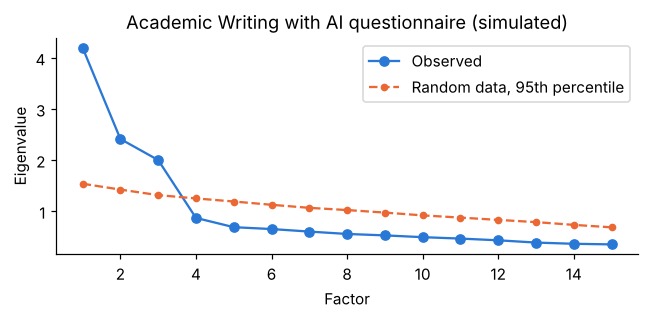

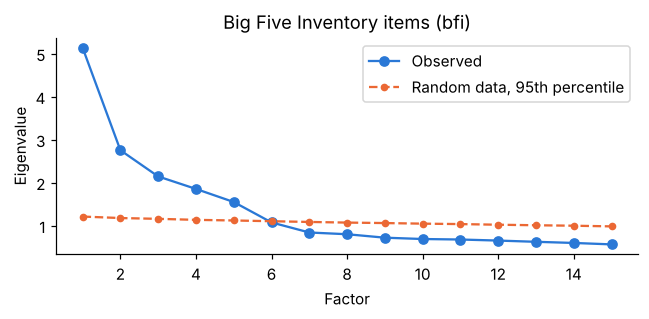

In [2]:
results = {}
for name, rev in [("writing_ai_simulated", ["CE4"]), ("bfi", ["A1", "C4", "C5", "E1", "E2", "O2", "O5"])]:
    df, meta = load(name)
    X = ps.reverse(ps.listwise(df.to_numpy(float)), [df.columns.get_loc(c) for c in rev], *meta["scale"])
    R = ps.corr(X)
    k, per_item = ps.kmo(R)
    chi2, dof, p = ps.bartlett(R, len(X))
    eig = np.sort(np.linalg.eigvalsh(R))[::-1]
    iters = 50 if len(X) * X.shape[1] > 40000 else 100
    pa = ps.parallel_analysis(len(X), X.shape[1], iters, 2026, 95)
    n_factors = int(np.argmax(eig <= pa)) if (eig <= pa).any() else len(eig)
    results[name] = dict(n=len(X), kmo=k, bartlett_chi2=chi2, df=dof, p=p, suggested_factors=n_factors)
    plt.figure(figsize=(6, 3))
    plt.plot(range(1, 16), eig[:15], "o-", color="#2a78d6", label="Observed")
    plt.plot(range(1, 16), pa[:15], "o--", color="#eb6834", ms=4, label="Random data, 95th percentile")
    plt.title(meta["name"]); plt.xlabel("Factor"); plt.ylabel("Eigenvalue"); plt.legend(); plt.tight_layout()
pd.DataFrame(results).T